***
<center>IMPORTS</center>

In [1]:
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.api import VAR
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import numpy as np
from sklearn.metrics import mean_squared_error

***
<center>Dwnd file</center>

In [5]:
file = pd.read_csv('data.csv', index_col='date', parse_dates=True)

df = file[['infl', 'key_rate']]

In [6]:
df.head()

,infl,key_rate
date,,
2013-09-01,6.14,5.5
2013-10-01,6.27,5.5
2013-11-01,6.50,5.5
2013-12-01,6.47,5.5
2014-01-01,6.07,5.5


In [7]:
d = df.diff().dropna()

In [10]:
train = d.loc[:'2024-12']
test = d.loc['2025-01':]

In [13]:
len(train) + len(test) == len(d)

True

***
Модель

In [15]:
model = VAR(train)

print(model.select_order(12).summary())

 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0        1.202       1.247       3.325       1.220
1       0.5693     0.7065*       1.767     0.6251*
2       0.5843      0.8129       1.794      0.6772
3       0.6192      0.9393       1.858      0.7492
4       0.6607       1.072       1.937      0.8278
5       0.6846       1.188       1.985      0.8889
6       0.7329       1.327       2.084      0.9743
7       0.7841       1.470       2.196       1.063
8       0.8047       1.582       2.244       1.120
9       0.8418       1.711       2.332       1.195
10      0.7872       1.747       2.212       1.177
11      0.7981       1.850       2.241       1.225
12     0.5202*       1.663      1.702*      0.9846
--------------------------------------------------


C:\Users\marr0\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


- BIC выбирает лаг 1, AIC — лаг 12 (эффект базы).
- VAR(12) слишком сложная для 135 наблюдений и может переобучиться.

**Выбрана модель VAR(1).**

In [16]:
res = model.fit(1)
print(res.summary())

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Wed, 18, Nov, 2026
Time:                     12:15:05
--------------------------------------------------------------------
No. of Equations:         2.00000    BIC:                   0.543375
Nobs:                     134.000    HQIC:                  0.466349
Log likelihood:          -401.988    FPE:                    1.51231
AIC:                     0.413621    Det(Omega_mle):         1.44680
--------------------------------------------------------------------
Results for equation infl
                 coefficient       std. error           t-stat            prob
------------------------------------------------------------------------------
const              -0.034401         0.072573           -0.474           0.635
L1.infl             0.318639         0.063656            5.006           0.000
L1.key_rate         0.450752         0.050180            8.983       

***
Тест Грейнджера

In [17]:
print(res.test_causality('infl', ['key_rate']).summary())
print(res.test_causality('key_rate', ['infl']).summary())

Granger causality F-test. H_0: key_rate does not Granger-cause infl. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value    df   
----------------------------------------------
         80.69          3.877   0.000 (1, 262)
----------------------------------------------
Granger causality F-test. H_0: infl does not Granger-cause key_rate. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value    df   
----------------------------------------------
         1.029          3.877   0.311 (1, 262)
----------------------------------------------


Прошлая ставка помогает прогнозировать инфляцию (p < 0.001), а прошлая
инфляция ставку — нет (p = 0.31). Скорее всего, ЦБ меняет ставку заранее,
глядя на прогнозы, поэтому ставка и «опережает» инфляцию.

***
функция отклика (IRF)

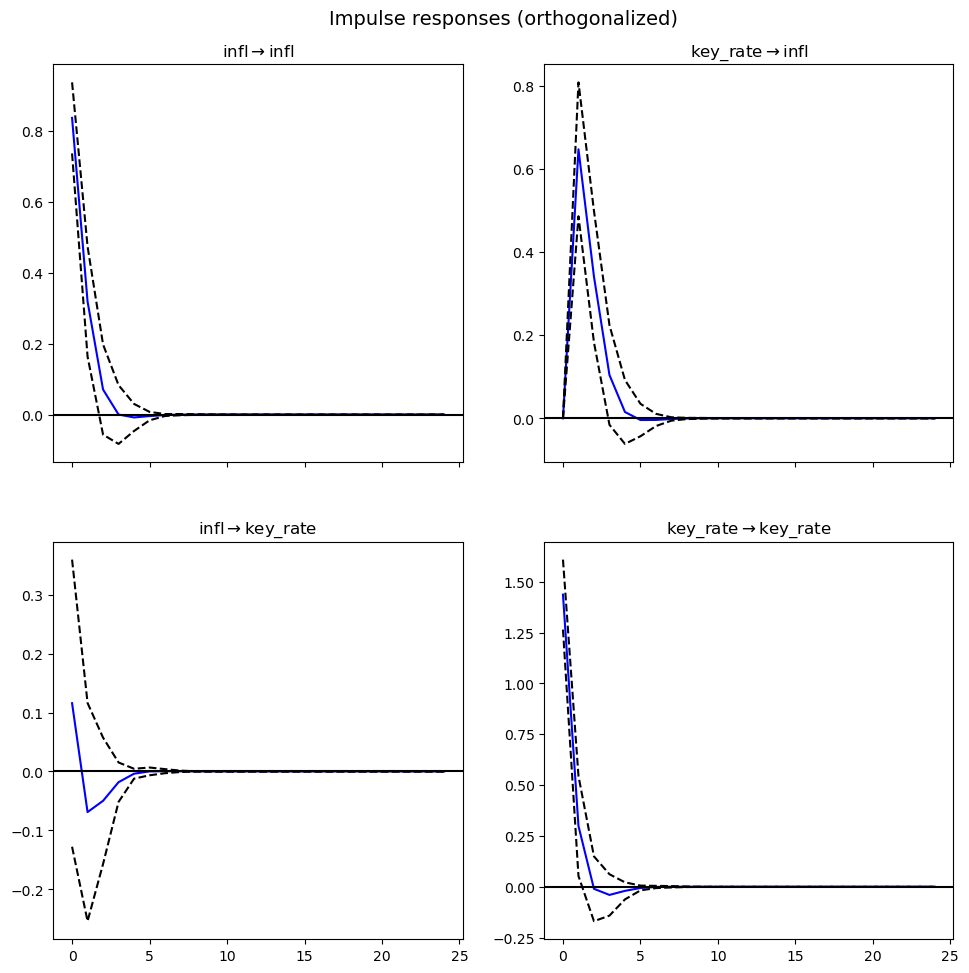

In [18]:
irf = res.irf(24)
irf.plot(orth=True)
plt.show()

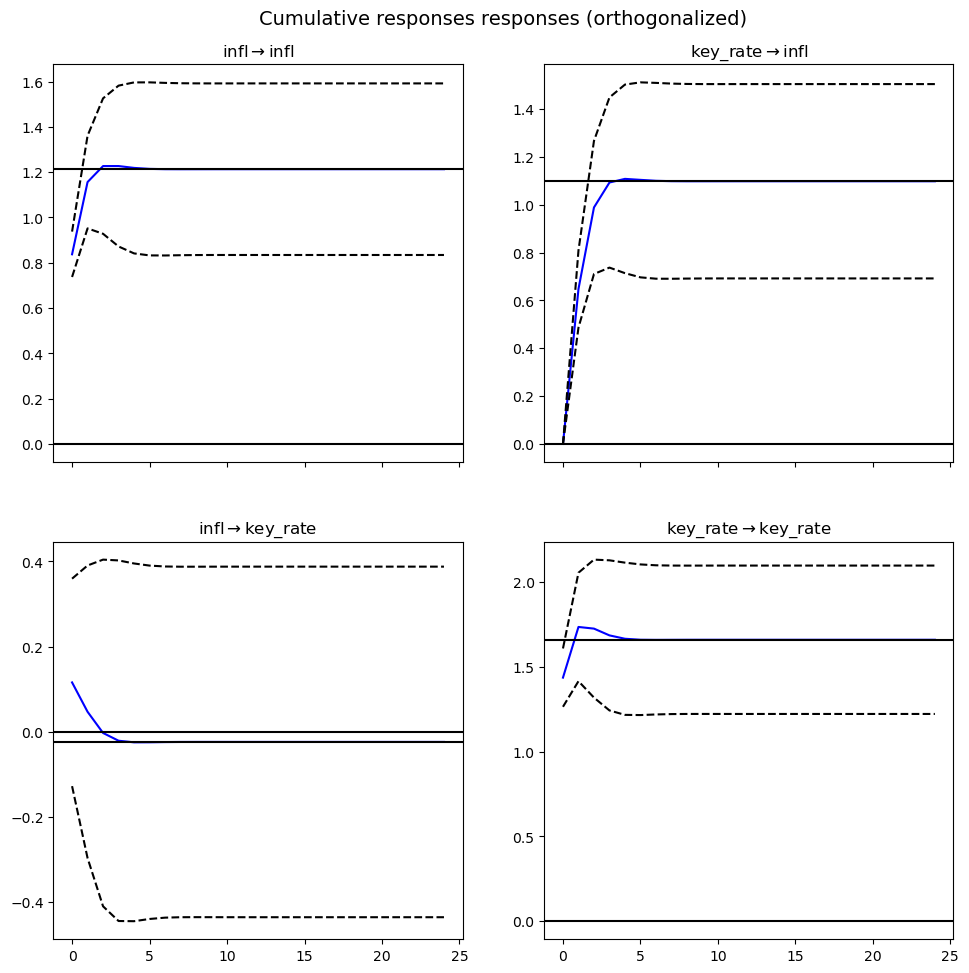

In [19]:
irf.plot_cum_effects(orth=True)
plt.show()

После неожиданного повышения ставки инфляция в модели растёт: быстрее
всего через месяц, потом рост затухает за ~5 месяцев, а инфляция в итоге
выше примерно на 1 п.п. На деле повышение ставки снижает инфляцию,
просто с задержкой. Модель видит, что ЦБ поднимает ставку перед ростом
цен, и путает реакцию с причиной (известный эффект price puzzle). Чтобы
это исправить, нужны ожидания, курс и другие факторы, на которые
смотрит ЦБ.

In [20]:
# прогноз изменений на 21 месяц вперёд
fc = res.forecast(train.values[-1:], steps=len(test))
fc = pd.DataFrame(fc, index=test.index, columns=train.columns)

# из изменений — обратно в уровень инфляции
last = df.loc[:'2024-12'].iloc[-1]
pred_var = fc.cumsum() + last

# ошибка
actual = df.loc['2025-01':, 'infl']
rmse_var = np.sqrt(mean_squared_error(actual, pred_var['infl']))
print(f'RMSE VAR(1): {rmse_var:.2f} п.п.')

RMSE VAR(1): 3.08 п.п.


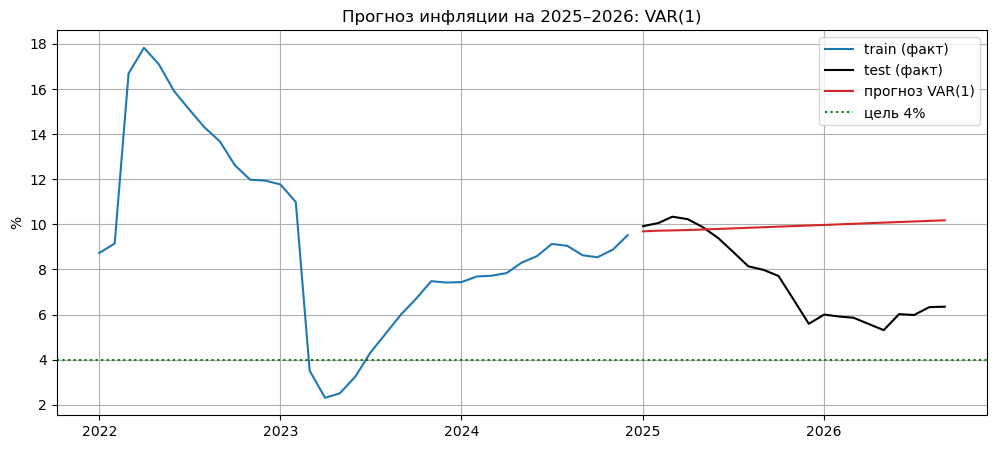

In [21]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df.loc['2022':'2024-12', 'infl'], label='train (факт)', color='tab:blue')
ax.plot(actual, label='test (факт)', color='black')
ax.plot(pred_var['infl'], label='прогноз VAR(1)', color='tab:red')
ax.axhline(4, color='green', linestyle=':', label='цель 4%')
ax.set_title('Прогноз инфляции на 2025–2026: VAR(1)')
ax.set_ylabel('%')
ax.legend()
ax.grid()
plt.show()

### Прогноз VAR и сравнение

| Модель | RMSE, п.п. |
|---|---|
| SARIMA | 1.33 |
| наивный | 2.68 |
| VAR(1) | 3.08 |

VAR прогнозирует хуже всех. В конце 2024 г. ставка была на пике, и по
логике модели (price puzzle) это значит дальнейший рост инфляции, хотя
на деле она пошла вниз. Кроме того, в VAR(1) нет эффекта базы, который
был у SARIMA. Добавление ставки само по себе прогноз не улучшило —
модели нужны факторы, на которые смотрит ЦБ: ожидания, курс, кредитование.